# Практическая работа № 9. Метод опорных векторов

**Вариант А**

## Цель

Сравнить границы решения SVM с линейным и RBF-ядром и проверить, как изменение C влияет на RBF-модель.

## 1. Данные и масштабирование

Шаблона в папке не было, поэтому используем `make_moons`. Масштабировщик обучаем на 225 обучающих точках и применяем также к 75 тестовым точкам.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

features, labels = make_moons(n_samples=300, noise=0.25, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.25, stratify=labels, random_state=42
)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 2. Построение границы решения

Сплошная линия соответствует уровню 0, пунктир — уровням −1 и +1. Обводка показывает опорные векторы. На графиках изображена обучающая выборка.

In [2]:
def draw_boundary(ax, model, features, labels, xx, yy, title):
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    scores = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, scores > 0, levels=[-0.5, 0.5, 1.5],
                colors=["#dcecff", "#ffe4cd"], alpha=0.8)
    ax.contour(xx, yy, scores, levels=[-1, 0, 1], colors="#334155",
               linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    for label, color in enumerate(["#2563eb", "#ea580c"]):
        points = features[labels == label]
        ax.scatter(points[:, 0], points[:, 1], c=color, s=18, alpha=0.85)
    vectors = model.support_vectors_
    ax.scatter(vectors[:, 0], vectors[:, 1], s=48, facecolors="none",
               edgecolors="#111827", linewidths=0.8)
    ax.set(title=title, xlabel="Признак 1", ylabel="Признак 2")
    ax.set_aspect("equal")

## 3. Обучение и сравнение

Сравниваем линейное ядро и RBF при C = 1, затем повторяем эксперимент с RBF при C = 0.1. Параметр gamma для RBF остаётся равным `scale`.

linear C=1 train=0.8800 test=0.8533 support=73
rbf    C=1 train=0.9067 test=0.8933 support=72
rbf    C=0.1 train=0.8800 test=0.8800 support=126


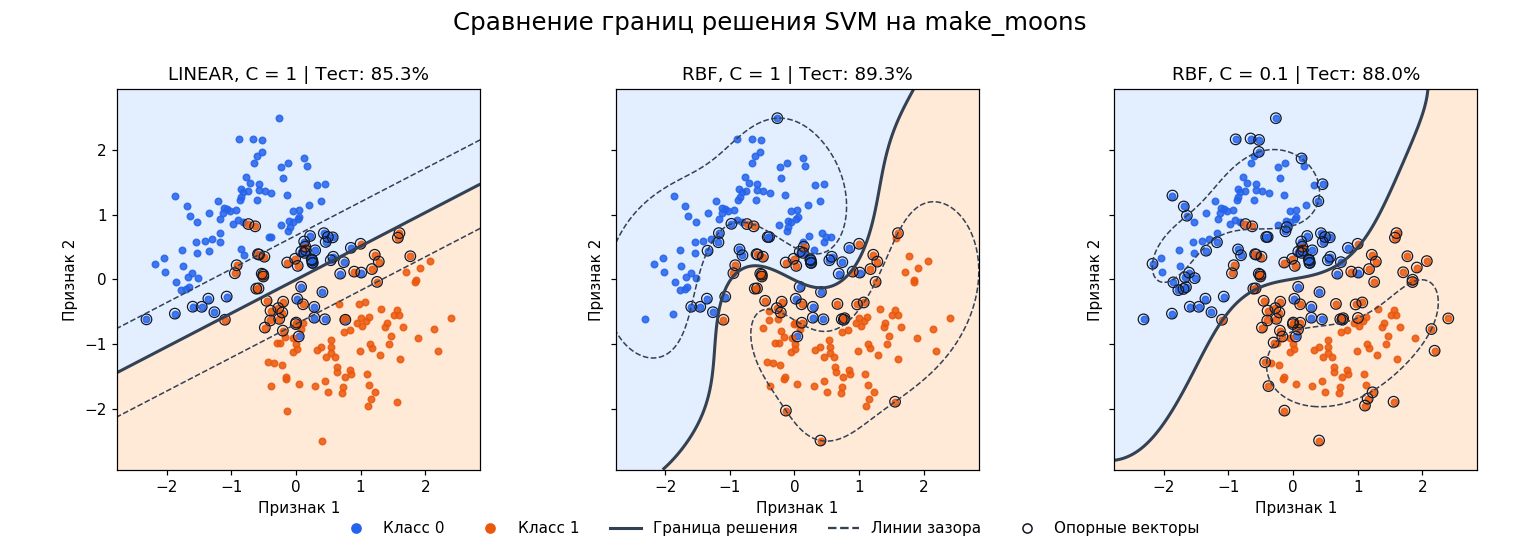

In [3]:
x_axis = np.linspace(x_train[:, 0].min() - 0.45, x_train[:, 0].max() + 0.45, 350)
y_axis = np.linspace(x_train[:, 1].min() - 0.45, x_train[:, 1].max() + 0.45, 350)
xx, yy = np.meshgrid(x_axis, y_axis)

experiments = [("linear", 1.0), ("rbf", 1.0), ("rbf", 0.1)]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharex=True, sharey=True)
for ax, (kernel, c_value) in zip(axes, experiments):
    model = SVC(kernel=kernel, C=c_value, gamma="scale")
    model.fit(x_train, y_train)
    train_score = model.score(x_train, y_train)
    test_score = model.score(x_test, y_test)
    title = f"{kernel.upper()}, C = {c_value:g} | Тест: {test_score:.1%}"
    draw_boundary(ax, model, x_train, y_train, xx, yy, title)
    print(f"{kernel:6s} C={c_value:g} train={train_score:.4f} "
          f"test={test_score:.4f} support={model.n_support_.sum()}")

fig.suptitle("Сравнение границ решения SVM на make_moons", fontsize=16)
fig.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", color="#2563eb", label="Класс 0"),
    Line2D([], [], marker="o", linestyle="none", color="#ea580c", label="Класс 1"),
    Line2D([], [], color="#334155", linewidth=2, label="Граница решения"),
    Line2D([], [], color="#334155", linestyle="--", label="Линии зазора"),
    Line2D([], [], marker="o", linestyle="none", markerfacecolor="none",
           markeredgecolor="#111827", label="Опорные векторы"),
], loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 0.94))
plt.show()

## Результаты

| Ядро | C | Точность на обучении | Точность на тесте | Опорные векторы |
| --- | ---: | ---: | ---: | ---: |
| Linear | 1 | 88.00% | 85.33% | 73 |
| RBF | 1 | 90.67% | 89.33% | 72 |
| RBF | 0.1 | 88.00% | 88.00% | 126 |

## Вывод

При C = 1 ядро RBF лучше разделило эти данные. Оно правильно классифицировало 67 из 75 тестовых точек, а линейное ядро — 64 из 75. Линейная модель проводит прямую через области, где точки разных классов перемешаны. RBF строит изогнутую границу, которая лучше следует форме полумесяцев.

При уменьшении C с 1 до 0.1 граница RBF стала менее изогнутой между полумесяцами. Меньший штраф за ошибки и нарушения зазора позволил модели слабее подстраиваться под отдельные точки. Число опорных векторов выросло с 72 до 126, а точность на тесте снизилась с 89.33% до 88.00%.